In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image

In [2]:
data = pd.read_csv('/content/20_26_PLTable.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Team    140 non-null    object
 1   Abb     140 non-null    object
 2   Points  140 non-null    int64 
 3   Played  140 non-null    int64 
 4   Won     140 non-null    int64 
 5   Lost    140 non-null    int64 
 6   Draw    140 non-null    int64 
 7   GD      140 non-null    int64 
 8   GF      140 non-null    int64 
 9   GA      140 non-null    int64 
 10  Season  140 non-null    object
dtypes: int64(8), object(3)
memory usage: 12.2+ KB


In [3]:
# Check for values of 0
data.isin([0]).any()

,0
Team,False
Abb,False
Points,False
Played,False
Won,True
Lost,False
Draw,False
GD,True
GF,False
GA,False


In [4]:
# Remove 0 values
data = data[data['Played'] != 0]
data.head()

,Team,Abb,Points,Played,Won,Lost,Draw,GD,GF,GA,Season
0,Arsenal,ARS,45,19,14,2,3,25,37,12,25/26
1,Manchester City,MCI,41,19,13,4,2,26,43,17,25/26
2,Aston Villa,AVL,39,19,12,4,3,7,30,23,25/26
3,Liverpool,LIV,33,19,10,6,3,4,30,26,25/26
4,Chelsea,CHE,30,19,8,5,6,11,32,21,25/26


In [5]:
# Check for duplicates
data.duplicated().sum()

np.int64(0)

In [6]:
# New features

# Remove / from Season and converting to int
data['Season'] = data['Season'].astype(str).str.replace('/', '').astype(int)

# Add team positions
data['Pos'] = data.groupby('Season').cumcount() + 1

# Move Pos to be the first column
first_col = data.pop('Pos')
data.insert(0, 'Pos', first_col)

# EXCLUDE AS DATA LEAKAGE - Based on the Pos field which I'm trying to predict
# # Group by team name and count number of seasons in PL
seasons_pl = data.groupby('Team')['Season'].count()
data['Num of Seasons'] = data['Team'].map(seasons_pl)

# Team number
data['Team Num'] = data['Team'].factorize()[0] + 1

# 3 year rolling averages, sort by team and season first
data = data.sort_values(by=['Team', 'Season'])

data['3yr History'] = (data.groupby('Team').cumcount().ge(3).astype(int))
data['2yr History'] = (data.groupby('Team').cumcount().ge(2).astype(int))
data['AvgPoints 3yr'] = data.groupby('Team')['Points'].rolling(3).mean().round(0).reset_index(0, drop=True)
data['AvgGD 3yr'] = data.groupby('Team')['GD'].rolling(3).mean().round(0).reset_index(0, drop=True)
data['AvgGF 3yr'] = data.groupby('Team')['GF'].rolling(3).mean().round(0).reset_index(0, drop=True)
data['AvgGA 3yr'] = data.groupby('Team')['GA'].rolling(3).mean().round(0).reset_index(0, drop=True)

# Set back to original index
data = data.sort_index()

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 140 entries, 0 to 139
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Pos             140 non-null    int64  
 1   Team            140 non-null    object 
 2   Abb             140 non-null    object 
 3   Points          140 non-null    int64  
 4   Played          140 non-null    int64  
 5   Won             140 non-null    int64  
 6   Lost            140 non-null    int64  
 7   Draw            140 non-null    int64  
 8   GD              140 non-null    int64  
 9   GF              140 non-null    int64  
 10  GA              140 non-null    int64  
 11  Season          140 non-null    int64  
 12  Num of Seasons  140 non-null    int64  
 13  Team Num        140 non-null    int64  
 14  3yr History     140 non-null    int64  
 15  2yr History     140 non-null    int64  
 16  AvgPoints 3yr   88 non-null     float64
 17  AvgGD 3yr       88 non-null     float64


In [7]:
# Adding a promoted column
data = data.sort_values(['Team Num', 'Season'])

prev_season = data.groupby('Team Num')['Season'].shift(1)

# Gap between seasons
data['Season Gap'] = data['Season'] - prev_season

# Promoted if gap is NOT equal to 101 (or if first season for that team)
data['Promoted'] = ((data['Season Gap'] != 101) | (prev_season.isna())).astype(int)

# Drop helper column
data = data.drop(columns=['Season Gap'])

# Set back to original index
data = data.sort_index()

In [8]:
#data = data.drop(['Team'], axis=1)
data.head(45)

,Pos,Team,Abb,Points,Played,Won,Lost,Draw,GD,GF,...,Season,Num of Seasons,Team Num,3yr History,2yr History,AvgPoints 3yr,AvgGD 3yr,AvgGF 3yr,AvgGA 3yr,Promoted
0,1,Arsenal,ARS,45,19,14,2,3,25,37,...,2526,7,1,1,1,69.0,41.0,66.0,25.0,0
1,2,Manchester City,MCI,41,19,13,4,2,26,43,...,2526,7,2,1,1,68.0,39.0,70.0,32.0,0
2,3,Aston Villa,AVL,39,19,12,4,3,7,30,...,2526,7,3,1,1,58.0,10.0,55.0,45.0,0
3,4,Liverpool,LIV,33,19,10,6,3,4,30,...,2526,7,4,1,1,66.0,31.0,67.0,36.0,0
4,5,Chelsea,CHE,30,19,8,5,6,11,32,...,2526,7,5,1,1,54.0,15.0,58.0,42.0,0
5,6,Manchester United,MUN,30,19,8,5,6,4,33,...,2526,7,6,1,1,44.0,-2.0,45.0,47.0,0
6,7,Sunderland,SUN,29,19,7,4,8,2,20,...,2526,1,7,0,0,NaN,NaN,NaN,NaN,1
7,8,Everton,EVE,28,19,8,7,4,0,20,...,2526,7,8,1,1,39.0,-4.0,34.0,38.0,0
8,9,Brentford,BRE,27,19,8,8,3,2,28,...,2526,5,9,1,1,41.0,1.0,50.0,49.0,0
9,10,Crystal Palace,CRY,27,19,7,6,6,1,22,...,2526,7,10,1,1,43.0,0.0,43.0,43.0,0


In [ ]:
data.to_csv('20_26_PLTable_Features_simplified.csv', index=False)

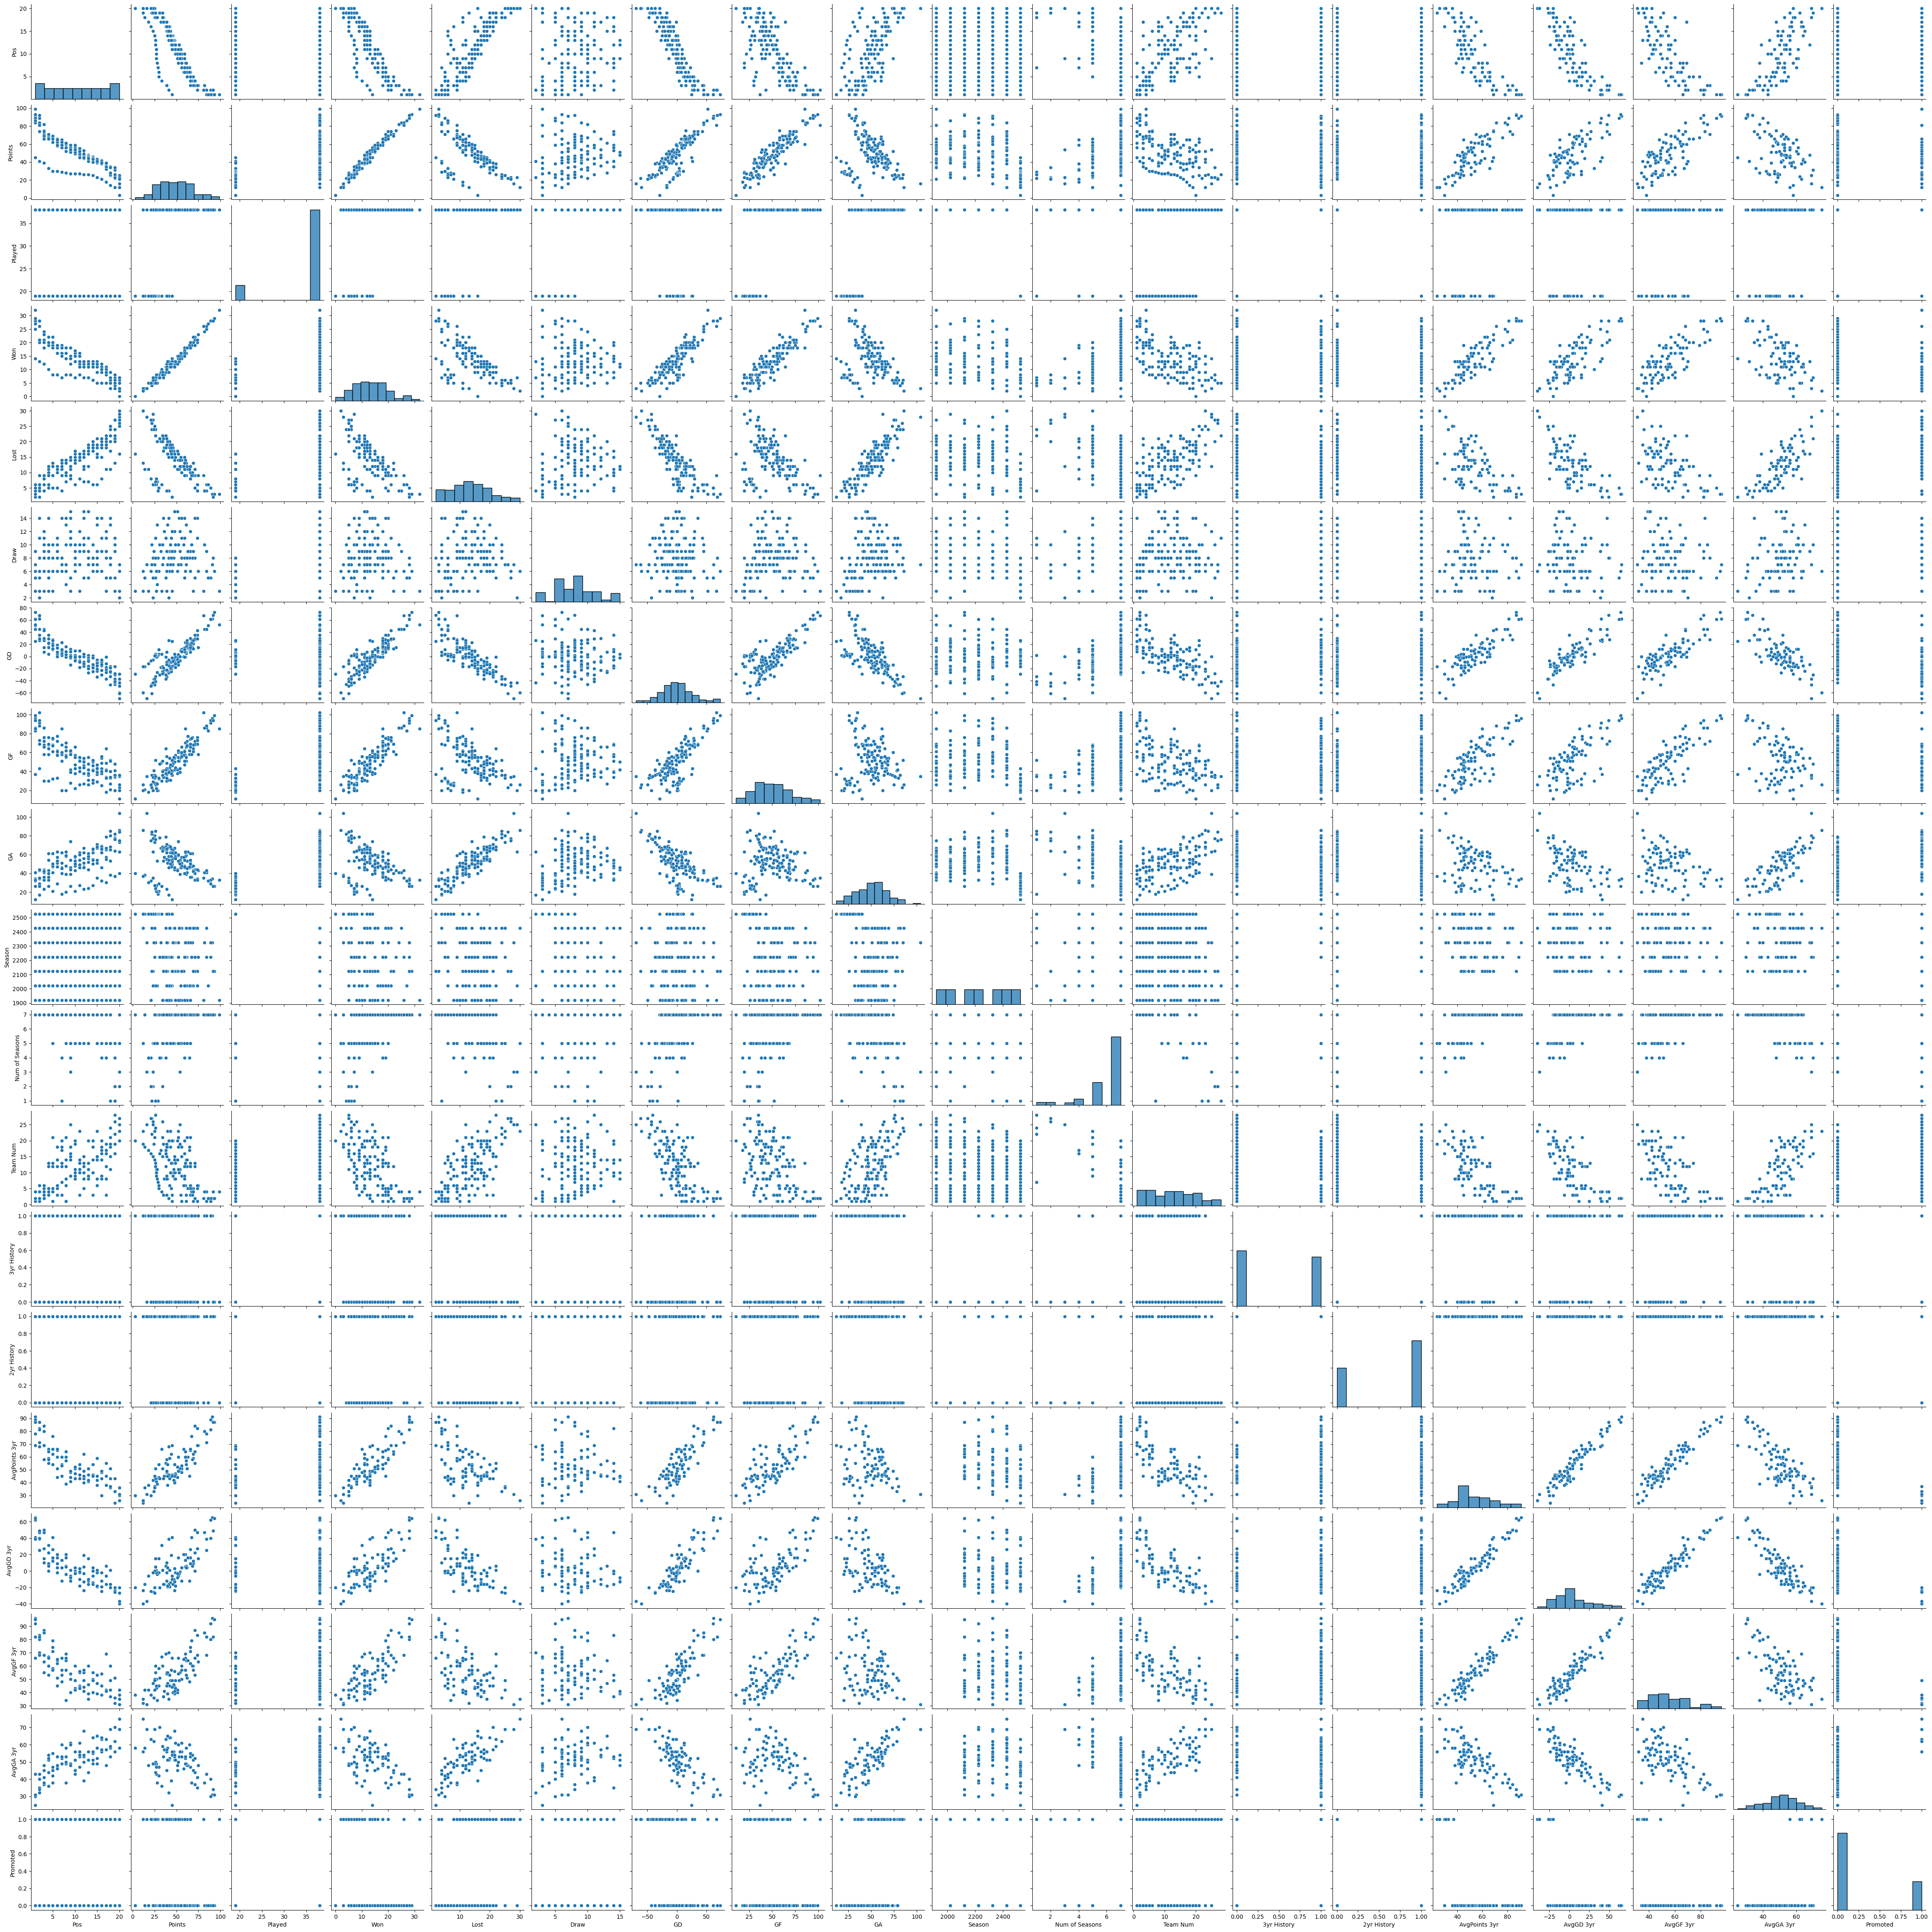

<Figure size 4750x4750 with 0 Axes>

In [9]:
pairplot = sns.pairplot(data)
# Save as png
pairplot.savefig('pairplot_simplified26.png')
# Clean pairplot
plt.clf()
# Display image
Image(filename= 'pairplot_simplified26.png')